# 00 — Розвідувальний аналіз: E Commerce Dataset (відтік клієнтів)

Домен E-commerce, ТЗ ЛР №1 (розділ 4). Захищені ознаки: `CityTier` (географія, основна) і `Gender`; `PreferredLoginDevice` — потенційний проксі. Аналіз лише описовий: жодних статистик, які потім потраплять у конвеєр, тут не обчислюється й не зберігається.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings("ignore", message="Bins whose width are too small")
pd.set_option("display.width", 160)
df = pd.read_csv(ROOT / "data/processed/ecommerce_churn_mar.csv")
manifest = json.loads((ROOT / "data/processed/injection_manifest.json").read_text(encoding="utf-8"))
df.shape, manifest["churn_share"]

((5630, 19), 0.1684)

## Джерело, очищення міток і пропуски

Сирий файл містить дублікати міток однієї категорії (`Phone`/`Mobile Phone`, `CC`/`Credit Card`, `COD`/`Cash on Delivery`, `Mobile`/`Mobile Phone`) — зведено в `scripts/prepare_data.py`. Природні пропуски — лише ≤ 5.5 % у семи колонках, тож для демонстрації другої і третьої гілок політики додано MAR-пропуски, залежні від спостережуваних незахищених ознак, і одну структурну відсутність.

In [2]:
pd.DataFrame({'до': manifest['missing_share_before'], 'після': manifest['missing_share_after']}).fillna(0).sort_values('після', ascending=False)

,до,після
OrderAmountHikeFromlastYear,0.0471,0.6290
CashbackAmount,0.0000,0.2213
PreferredPaymentMode,0.0000,0.1854
DaySinceLastOrder,0.0545,0.0545
Tenure,0.0469,0.0469
OrderCount,0.0458,0.0458
CouponUsed,0.0455,0.0455
HourSpendOnApp,0.0453,0.0453
WarehouseToHome,0.0446,0.0446


In [3]:
print(json.dumps(manifest['mar_rules'] + [manifest['structural_rule']], ensure_ascii=False, indent=2))

[
  {
    "column": "CashbackAmount",
    "depends_on": "DaySinceLastOrder",
    "condition": "<= 2",
    "probability": 0.65,
    "legend": "кешбек за нещодавнє замовлення ще не нараховано"
  },
  {
    "column": "PreferredPaymentMode",
    "depends_on": "OrderCount",
    "condition": "<= 1",
    "probability": 0.6,
    "legend": "без історії замовлень улюблений спосіб оплати невідомий"
  },
  {
    "column": "OrderAmountHikeFromlastYear",
    "depends_on": "Tenure",
    "condition": "< 12",
    "legend": "приріст суми замовлень відносно минулого року не визначений для клієнтів, які з нами менше року"
  }
]


## Цільова змінна та базові показники у захищених групах

Частки відтоку між містами різного рівня і між статями відрізняються — це визначає вибір між DPR і EOR (контрольне питання блоку В).

In [4]:
print('churn:', df['Churn'].mean().round(4))
for p in ['CityTier', 'Gender', 'PreferredLoginDevice']:
    display(df.groupby(p)['Churn'].agg(['mean', 'size']).round(3))

churn: 0.1684


,mean,size
CityTier,,
1,0.145,3666
2,0.198,242
3,0.214,1722


,mean,size
Gender,,
Female,0.155,2246
Male,0.177,3384


,mean,size
PreferredLoginDevice,,
Computer,0.198,1634
Mobile Phone,0.156,3996


## Розподіли числових ознак

Асиметрія (`CashbackAmount`, `WarehouseToHome`, `NumberOfAddress`) — аргумент для Yeo–Johnson у чутливій до масштабу гілці та для квантильних бінів у інваріантній.

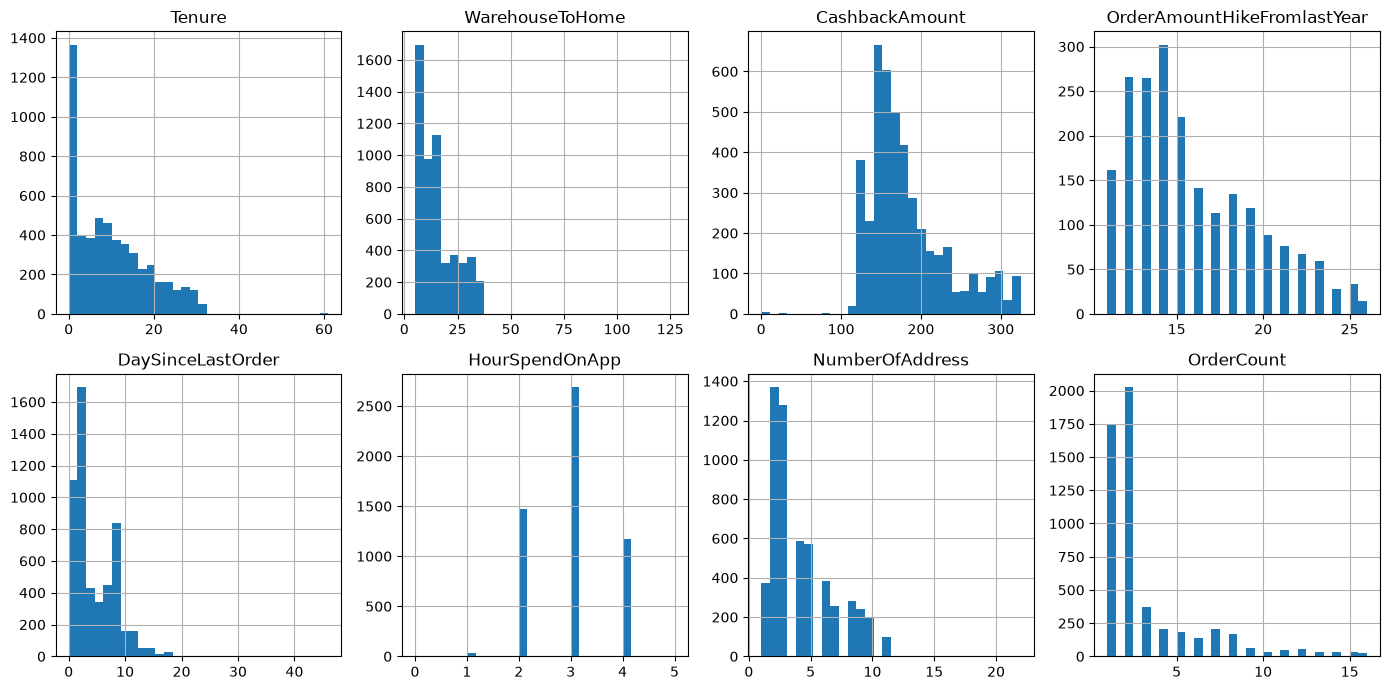

Tenure                         0.74
WarehouseToHome                1.62
CashbackAmount                 1.06
OrderAmountHikeFromlastYear    0.79
DaySinceLastOrder              1.19
HourSpendOnApp                -0.03
NumberOfAddress                1.09
OrderCount                     2.20
dtype: float64

In [5]:
num = ['Tenure','WarehouseToHome','CashbackAmount','OrderAmountHikeFromlastYear','DaySinceLastOrder','HourSpendOnApp','NumberOfAddress','OrderCount']
axes = df[num].hist(bins=30, figsize=(14, 7), layout=(2, 4))
plt.tight_layout(); plt.show()
df[num].skew().round(2)

## Категоріальні ознаки після очищення

In [6]:
for c in ['PreferredLoginDevice','PreferredPaymentMode','PreferedOrderCat','MaritalStatus','SatisfactionScore']:
    print(c, df[c].value_counts(dropna=False).to_dict())

PreferredLoginDevice {'Mobile Phone': 3996, 'Computer': 1634}
PreferredPaymentMode {'Debit Card': 1884, 'Credit Card': 1455, nan: 1044, 'E wallet': 500, 'Cash on Delivery': 417, 'UPI': 330}
PreferedOrderCat {'Mobile Phone': 2080, 'Laptop & Accessory': 2050, 'Fashion': 826, 'Grocery': 410, 'Others': 264}
MaritalStatus {'Married': 2986, 'Single': 1796, 'Divorced': 848}
SatisfactionScore {3: 1698, 1: 1164, 5: 1108, 4: 1074, 2: 586}


## Проксі захищених ознак

V Крамера між `PreferredLoginDevice` і захищеними ознаками, а також між захищеними ознаками між собою. Число з `artifacts/analysis.json` (скрипт `scripts/analyze.py`) — той самий розрахунок для всіх ознак.

In [7]:
from scipy.stats import chi2_contingency
def cramers_v(a, b):
    t = pd.crosstab(a, b); chi2 = chi2_contingency(t, correction=False)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))
pairs = [('PreferredLoginDevice','CityTier'), ('PreferredLoginDevice','Gender'), ('CityTier','Gender'), ('PreferredPaymentMode','CityTier'), ('PreferedOrderCat','Gender')]
pd.DataFrame([(a, b, round(cramers_v(df[a].fillna('NA'), df[b]), 3)) for a, b in pairs], columns=['ознака','захищена','V'])

,ознака,захищена,V
0,PreferredLoginDevice,CityTier,0.012
1,PreferredLoginDevice,Gender,0.016
2,CityTier,Gender,0.049
3,PreferredPaymentMode,CityTier,0.396
4,PreferedOrderCat,Gender,0.074
